# Customer Churn Prediction — Data Exploration and Initial Preprocessing
This notebook contains the work completed so far: loading and inspecting the dataset, checking data quality, exploring churn patterns, handling the missing InternetService values, separating features and target, and one-hot encoding categorical features.

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('./archive/customer_churn_data.csv')
pd.set_option('display.max_rows', None)

## 1. Inspect the dataset

In [2]:
# Uncomment these lines when you want to inspect the corresponding output.
# df.describe()
# df[df['InternetService'].isna()]
# df.isna().sum()

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerID       1000 non-null   int64  
 1   Age              1000 non-null   int64  
 2   Gender           1000 non-null   object 
 3   Tenure           1000 non-null   int64  
 4   MonthlyCharges   1000 non-null   float64
 5   ContractType     1000 non-null   object 
 6   InternetService  703 non-null    object 
 7   TotalCharges     1000 non-null   float64
 8   TechSupport      1000 non-null   object 
 9   Churn            1000 non-null   object 
dtypes: float64(2), int64(3), object(5)
memory usage: 78.2+ KB


## 2. Check duplicates and categorical values

In [3]:
duplicate_rows = df[df.duplicated()]

gender_unique = df['Gender'].unique()
contract_unique = df['ContractType'].unique()
internet_service_unique = df['InternetService'].unique()
tech_support_unique = df['TechSupport'].unique()
churn_unique = df['Churn'].unique()

# Display these when needed:
# print('Gender:', gender_unique)
# print('Contract type:', contract_unique)
# print('Internet service:', internet_service_unique)
# print('Tech support:', tech_support_unique)
# print('Churn:', churn_unique)
# print('Number of duplicate rows:', len(duplicate_rows))

## 3. Check numeric values and customer IDs

In [4]:
id_unique = df['CustomerID'].unique()
id_neg = df[df['CustomerID'] < 0]
age_neg = df[df['Age'] < 0]
tenure_neg = df[df['Tenure'] < 0]
monthly_charges_neg = df[df['MonthlyCharges'] < 0]
total_charges_neg = df[df['TotalCharges'] < 0]

# Display the checks when needed:
# print('Unique CustomerIDs:', len(id_unique))
# print('Negative CustomerIDs:', len(id_neg))
# print('Negative ages:', len(age_neg))
# print('Negative tenures:', len(tenure_neg))
# print('Negative monthly charges:', len(monthly_charges_neg))
# print('Negative total charges:', len(total_charges_neg))

## 4. Explore churn patterns

In [5]:
tenure_grouped = df.groupby('TechSupport')['Churn'].value_counts()
contract_grouped_churn = df.groupby('ContractType')['Churn'].value_counts()
tenure_grouped_churn = df.groupby('Tenure')['Churn'].value_counts()

# Group tenure into intervals to make the pattern easier to inspect.
max_tenure = df['Tenure'].max()
bin_edges = sorted(set([0, 12, 24, 36, 48, max_tenure]))
df['Tenure_Bins'] = pd.cut(
    df['Tenure'],
    bins=bin_edges,
    include_lowest=True
)
tenure_bins_grouped_churn = df.groupby('Tenure_Bins', observed=False)['Churn'].value_counts()

# Display these when needed:
# print(df['Churn'].value_counts())
# print(tenure_grouped)
# print(contract_grouped_churn)
# print(tenure_grouped_churn)
# print(tenure_bins_grouped_churn)

## 5. Handle missing InternetService values

In [6]:
# Treat a missing InternetService value as a separate category.
df['InternetService'] = df['InternetService'].fillna('No Internet Service')

print(df.columns)

Index(['CustomerID', 'Age', 'Gender', 'Tenure', 'MonthlyCharges',
       'ContractType', 'InternetService', 'TotalCharges', 'TechSupport',
       'Churn', 'Tenure_Bins'],
      dtype='object')


## 6. Separate input features (X) and target (y)

In [7]:
X = df[['Tenure', 'MonthlyCharges', 'ContractType', 'InternetService', 'TechSupport']].copy()
y = df['Churn'].copy()

print('X shape:', X.shape)
print('y shape:', y.shape)

X shape: (1000, 5)
y shape: (1000,)


## 7. One-hot encode categorical features
The categorical columns contain text labels. `pd.get_dummies()` converts each category into a numeric indicator column. This cell creates the encoded columns; the next step will be to combine them with the numeric features.

In [9]:
categorical_features = X[['ContractType', 'InternetService', 'TechSupport']]
dmy = pd.get_dummies(categorical_features, dtype=int)

print(dmy.columns)
display(dmy.head())
print('Encoded shape:', dmy.shape)

Index(['ContractType_Month-to-Month', 'ContractType_One-Year',
       'ContractType_Two-Year', 'InternetService_DSL',
       'InternetService_Fiber Optic', 'InternetService_No Internet Service',
       'TechSupport_No', 'TechSupport_Yes'],
      dtype='object')


,ContractType_Month-to-Month,ContractType_One-Year,ContractType_Two-Year,InternetService_DSL,InternetService_Fiber Optic,InternetService_No Internet Service,TechSupport_No,TechSupport_Yes
0,1,0,0,0,1,0,0,1
1,1,0,0,0,1,0,0,1
2,1,0,0,0,1,0,1,0
3,0,1,0,1,0,0,0,1
4,1,0,0,0,0,1,1,0


Encoded shape: (1000, 8)


Making the X to replace this ContractType and other 2 with this dmy

In [10]:
X = X.drop(columns=['ContractType', 'InternetService', 'TechSupport'])

X = pd.concat([X, dmy], axis=1)

print(X.head())
print(X.shape)

   Tenure  MonthlyCharges  ContractType_Month-to-Month  ContractType_One-Year  \
0       4           88.35                            1                      0   
1       0           36.67                            1                      0   
2       2           63.79                            1                      0   
3       8          102.34                            0                      1   
4      32           69.01                            1                      0   

   ContractType_Two-Year  InternetService_DSL  InternetService_Fiber Optic  \
0                      0                    0                            1   
1                      0                    0                            1   
2                      0                    0                            1   
3                      0                    1                            0   
4                      0                    0                            0   

   InternetService_No Internet Service  Tech

Manually Mapping the Yes and No with Numbers for easy working ( I DID THIS AFTER FULLY CHECKING THE WHOLE FEATURE BE WITH CAUTION FORCING LABELS LIKE THIS MUST ONLY BE DONE AFTER A GOOD WALKTHROUGH OF THE FEATURE  )

In [11]:
y = y.map({'No': 0, 'Yes': 1})

print(y.value_counts())

Churn
1    883
0    117
Name: count, dtype: int64


In [ ]:
print(X.info())
print(y.info())
print(X.isna().sum())
print(y.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Tenure                               1000 non-null   int64  
 1   MonthlyCharges                       1000 non-null   float64
 2   ContractType_Month-to-Month          1000 non-null   int64  
 3   ContractType_One-Year                1000 non-null   int64  
 4   ContractType_Two-Year                1000 non-null   int64  
 5   InternetService_DSL                  1000 non-null   int64  
 6   InternetService_Fiber Optic          1000 non-null   int64  
 7   InternetService_No Internet Service  1000 non-null   int64  
 8   TechSupport_No                       1000 non-null   int64  
 9   TechSupport_Yes                      1000 non-null   int64  
dtypes: float64(1), int64(9)
memory usage: 78.2 KB
None
<class 'pandas.core.series.Series'>
RangeIndex

Splitting the Dataset X and Y into train and test

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(800, 10)
(200, 10)
(800,)
(200,)


Now working on the Scaling, think of using Standard Scalar As we in the end DO Logistic regression. 

In [14]:
from sklearn.preprocessing import StandardScaler

Doing Scaling 

In [15]:
Std = StandardScaler()
X_train_scaled = Std.fit_transform(X_train) 
X_test_scaled = Std.transform(X_test)

print(X_train_scaled.shape)
print(X_test_scaled.shape)

(800, 10)
(200, 10)


Importing Logistic Regression for getting our classifications

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(random_state=50)
model.fit(X_train_scaled, y_train)
model_score = model.score(X_test_scaled, y_test)
mm = model.predict(X_test_scaled)
# print('Model score:', model_score)
# print('Predictions:', mm)

Model score: 0.97
[1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 0 0 1 1 0 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 0 1 1 1 1 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1
 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1]


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

In [ ]:
print('Confusion Matrix:\n', confusion_matrix(y_test, mm))
print('Classification Report:\n', classification_report(y_test, mm))


Confusion Matrix:
 [[ 17   6]
 [  0 177]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.74      0.85        23
           1       0.97      1.00      0.98       177

    accuracy                           0.97       200
   macro avg       0.98      0.87      0.92       200
weighted avg       0.97      0.97      0.97       200

[[2.66688879e-03 9.97333111e-01]
 [4.69164067e-07 9.99999531e-01]
 [3.67809475e-05 9.99963219e-01]
 [3.66818353e-08 9.99999963e-01]
 [2.16703779e-04 9.99783296e-01]]


In [28]:

from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

y_prob = model.predict_proba(X_test_scaled)[:,1]
fpr,tpr,thr = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)
print('ROC AUC Score:', auc)

ROC AUC Score: 0.9953328420535495


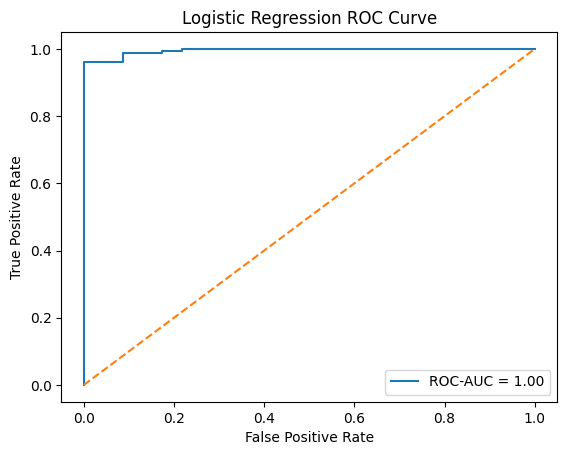

In [31]:
import matplotlib.pyplot as plt

plt.plot(fpr, tpr, label=f'ROC-AUC = {auc:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Logistic Regression ROC Curve')
plt.legend()
plt.show()

MAKING RANDOM FOREST TO CHECK THE PREDICTION SCORE OF THE DATASET. THIS IS AN ADDITIONAL CHECK WITH LOGISTIC REGRESSION.

In [32]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(random_state=50)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_prob = rf_model.predict_proba(X_test)[:, 1]

In [33]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, rf_pred))
print("Classification Report:\n", classification_report(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))

Accuracy: 1.0
Confusion Matrix:
 [[ 23   0]
 [  0 177]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        23
           1       1.00      1.00      1.00       177

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200

ROC-AUC: 1.0
